# Dogs vs Cats Image Classification with a CNN

A convolutional neural network (CNN) built with TensorFlow/Keras that classifies images as **cat** or **dog**.

**Workflow:** `Input -> Conv2D -> MaxPooling -> Flatten -> Fully Connected -> Output`

| Item | Value |
|---|---|
| Dataset | [Dogs vs Cats (Kaggle, `salader/dogsvscats`)](https://www.kaggle.com/datasets/salader/dogsvscats) |
| Train / validation images | 20,000 / 5,000 |
| Input size | 256 x 256 x 3 (RGB) |
| Task | Binary classification (sigmoid output) |
| Framework | TensorFlow / Keras |

## 1. Data Setup

Download the dataset from Kaggle (requires a `kaggle.json` API token) and extract it.

In [1]:
# Upload the Kaggle API token (kaggle.json)
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [2]:
# Install the Kaggle CLI and register the API token
!pip install -q kaggle

import os
import shutil

os.makedirs('/root/.kaggle', exist_ok=True)
shutil.move('kaggle.json', '/root/.kaggle/kaggle.json')

# The token must be readable only by the owner
os.chmod('/root/.kaggle/kaggle.json', 0o600)

In [3]:
# Download the Dogs vs Cats dataset
!kaggle datasets download -d salader/dogsvscats

Dataset URL: https://www.kaggle.com/datasets/salader/dogsvscats
License(s): unknown
100% 1.06G/1.06G [00:50<00:00, 22.7MB/s]



In [4]:
# Extract the archive into /content (creates /content/train and /content/test)
import zipfile

with zipfile.ZipFile('/content/dogsvscats.zip', 'r') as zip_ref:
    zip_ref.extractall('/content')

## 2. Imports

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential
from keras.layers import (Input, Conv2D, MaxPooling2D, Flatten,
                          Dense, BatchNormalization)

## 3. Data Loading and Preprocessing

- Images are read from folders; the class label is inferred from the folder name (`cats` / `dogs`).
- Every image is resized to 256 x 256 and batched (32 images per batch).
- Pixel values are scaled from `[0, 255]` to `[0, 1]` so training is faster and more stable.

In [8]:
# Training and validation datasets (labels inferred from sub-folder names)
train_ds = keras.utils.image_dataset_from_directory(
    directory='/content/train',
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(256, 256)
)

validation_ds = keras.utils.image_dataset_from_directory(
    directory='/content/test',
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(256, 256)
)

Found 20000 files belonging to 2 classes.
Found 5000 files belonging to 2 classes.


In [9]:
# Normalize pixel values to the range [0, 1]
def process(image, label):
    image = tf.cast(image / 255., tf.float32)
    return image, label

train_ds = train_ds.map(process)
validation_ds = validation_ds.map(process)

## 4. Model Architecture

Four convolution blocks extract features, then a stack of dense layers does the classification.

```
Input (256x256x3)
  -> [Conv2D -> BatchNorm -> MaxPool] x 4     (32, 64, 128, 256 filters)
  -> Flatten
  -> Dense 256 -> 128 -> 64 -> 32 -> 16       (ReLU, BatchNorm on the first four)
  -> Dense 1 (sigmoid)                        (probability of "dog")
```

An earlier variant that used `padding='valid'` in every convolution was tried first; using `'same'` padding in most
layers gave better results, so that version is kept below.

In [57]:
model = Sequential()

# ---- Input: 256 x 256 RGB image ----
model.add(Input(shape=(256, 256, 3)))

# ---- Block 1: 32 filters ----
# 'same' padding keeps the spatial size (256x256) after the convolution
model.add(Conv2D(32, kernel_size=(3, 3), padding="same", activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2), strides=2, padding='same'))   # -> 128x128

# ---- Block 2: 64 filters ----
# 'valid' padding (no padding) shrinks the map by 2 pixels (128 -> 126)
model.add(Conv2D(64, kernel_size=(3, 3), padding="valid", activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2), strides=2, padding='same'))   # -> 63x63

# ---- Block 3: 128 filters ----
model.add(Conv2D(128, kernel_size=(3, 3), padding="same", activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2), strides=2, padding='same'))   # -> 32x32

# ---- Block 4: 256 filters ----
model.add(Conv2D(256, kernel_size=(3, 3), padding="same", activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2), strides=2, padding='same'))   # -> 16x16

# ---- Flatten: 16 x 16 x 256 feature maps -> 65,536-length vector ----
model.add(Flatten())

# ---- Fully connected layers ----
model.add(Dense(256, activation='relu'))
model.add(BatchNormalization())

model.add(Dense(128, activation='relu'))
model.add(BatchNormalization())

model.add(Dense(64, activation='relu'))
model.add(BatchNormalization())

model.add(Dense(32, activation='relu'))
model.add(BatchNormalization())

model.add(Dense(16, activation='relu'))

# ---- Output: single sigmoid unit, probability that the image is a dog ----
model.add(Dense(1, activation='sigmoid'))

## 5. Compile and Train

- **Optimizer:** Adam
- **Loss:** binary cross-entropy (two classes, sigmoid output)
- **Metric:** accuracy
- Backpropagation runs automatically inside `model.fit()`: the loss is computed on each batch, gradients flow backward
  through every layer, and Adam updates the weights.

In [58]:
# Configure the learning process
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [59]:
# Layer-by-layer output shapes and parameter counts
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 256, 256, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 256, 256, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 126, 126, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 126, 126, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 63, 63, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 63, 63, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 63, 63, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 32, 32, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 32, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 65536)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 256)            │    16,777,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │             

 Total params: 17,213,505 (65.66 MB)

 Trainable params: 17,211,585 (65.66 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [81]:
# Train for 20 epochs, evaluating on the validation set after each epoch
history = model.fit(train_ds, epochs=20, validation_data=validation_ds)

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 78s 108ms/step - accuracy: 0.6701 - loss: 0.5980 - val_accuracy: 0.6918 - val_loss: 0.5766
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 63s 101ms/step - accuracy: 0.7710 - loss: 0.4762 - val_accuracy: 0.7496 - val_loss: 0.5039
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 67s 108ms/step - accuracy: 0.8178 - loss: 0.4005 - val_accuracy: 0.7690 - val_loss: 0.4743
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 63s 101ms/step - accuracy: 0.8619 - loss: 0.3242 - val_accuracy: 0.7984 - val_loss: 0.4585
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 67s 108ms/step - accuracy: 0.8930 - loss: 0.2566 - val_accuracy: 0.8398 - val_loss: 0.3898
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 83s 109ms/step - accuracy: 0.9291 - loss: 0.1709 - val_accuracy: 0.8576 - val_loss: 0.3821
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 63s 101ms/step - accuracy: 0.9506 - loss: 0.1265 - val_accuracy: 0.8378 - val_loss: 0.4011
Epoch 8/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 63s 101ms/step - accuracy: 0.9679 - loss: 0

## 6. Training Results

After 20 epochs the model reaches **99.4% training accuracy** and **90.1% validation accuracy**.

Validation accuracy improves from 69.2% to about 90% but fluctuates from epoch to epoch (for example, a dip to 83.6% at epoch 16),
and validation loss stops improving after epoch 13 while training loss keeps falling. This gap indicates **overfitting**; data
augmentation, dropout, or early stopping are natural next steps.

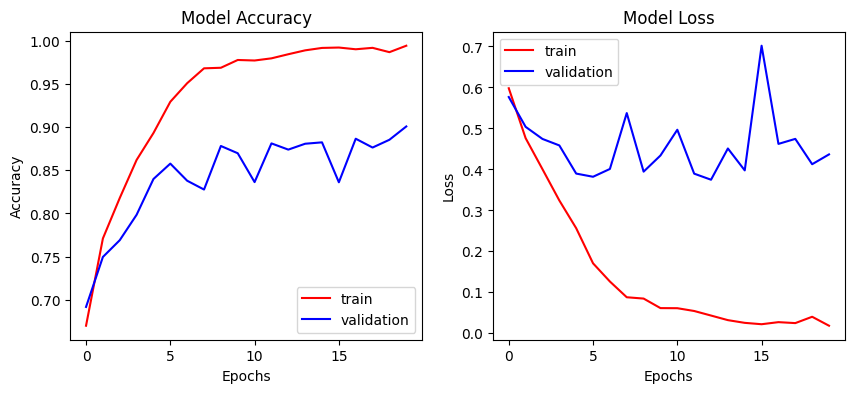

In [84]:
plt.figure(figsize=(10, 4))

# Accuracy curves
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], color='red', label='train')
plt.plot(history.history['val_accuracy'], color='blue', label='validation')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss curves
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], color='red', label='train')
plt.plot(history.history['val_loss'], color='blue', label='validation')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

## 7. Prediction on a New Image

`predict()` applies the same preprocessing used in training (RGB conversion, resize to 256 x 256, scaling to `[0, 1]`,
batch dimension) and thresholds the sigmoid output at 0.5.

In [65]:
def predict(image_path):
    """Classify a single image as Cat or Dog and display it with the confidence."""
    # Read the image (OpenCV loads BGR) and convert to RGB
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"Image not found: {image_path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Same preprocessing as training: resize, scale to [0, 1], add batch dimension
    img = cv2.resize(img, (256, 256))
    img = img / 255.0
    img = np.expand_dims(img, axis=0)

    # Sigmoid output = probability of class 1 (dog)
    probability = float(model.predict(img, verbose=0)[0][0])

    if probability >= 0.5:
        label, confidence = "Dog 🐶", probability * 100
    else:
        label, confidence = "Cat 🐱", (1 - probability) * 100

    # Show the image with its prediction
    plt.figure(figsize=(5, 5))
    plt.imshow(img[0])
    plt.title(f"{label}\nConfidence: {confidence:.2f}%")
    plt.axis('off')
    plt.show()

    print(f"Prediction: {label}")
    print(f"Dog Probability: {probability * 100:.2f}%")
    print(f"Cat Probability: {(1 - probability) * 100:.2f}%")

    return label, probability

In [ ]:
# Example: classify any image from the validation folder
import glob

sample_path = sorted(glob.glob('/content/test/dogs/*'))[0]
predict(sample_path)